# **Part 1: Visualization & Exploratory Data Analysis (EDA)**

### **Dataset Introduction**

In this project, we will work with the Palmer Penguins dataset, which contains measurements of penguins observed on islands near Antarctica.

Please download the dataset [penguins.csv](https://drive.google.com/file/d/1dv8A8v_sdf29p1At40S7KBslJPmBA3e9/view?usp=sharing) or from canvas.

### **Dataset Description**

Each row represents a penguin, and columns include:

- species – Penguin species
- island – Island where the penguin was found
- bill_length_mm – Bill length (mm)
- bill_depth_mm – Bill depth (mm)
- flipper_length_mm – Flipper length (mm)
- body_mass_g – Body mass (grams)
- sex – Sex of the penguin

Some values are missing, which makes this dataset ideal for practicing missing data handling.



Your task is to perform a comprehensive Exploratory Data Analysis (EDA) and visualization on the Palmer Penguins dataset. This project aims to deepen your understanding of data characteristics, relationships between variables, and effective data presentation using Python's data science libraries.

**Instructions:**

1.  **Load the Dataset:** Begin by loading the `penguins.csv` dataset into a pandas DataFrame.
2.  **Initial Data Inspection:** Perform an initial inspection to understand the dataset's structure. Display the first few rows, check data types and non-null values, and generate descriptive statistics.
3.  **Handle Missing Values:** Identify and address any missing values in the dataset. Clearly explain your chosen strategy for handling missing data (e.g., imputation, dropping rows/columns) and justify your decision.
4.  **Perform EDA and Visualization:** Conduct a thorough EDA, exploring distributions, relationships, and patterns within the data. You are required to use **at least three distinct types of visualizations** (e.g., histograms, scatter plots, box plots, bar charts). For each visualization:
    *   Justify your choice of plot type, explaining why it is suitable for the variables being analyzed.
    *   Clearly articulate what insights each visualization reveals about the data (e.g., distributions, correlations, outliers, group differences).
5.  **Summarize Key Findings:** Based on your EDA and visualizations, summarize the most important insights and observations about the Palmer Penguins dataset. Highlight any discovered patterns, trends, anomalies, or interesting relationships.
6.  **Final Task:** Present your complete EDA and visualization analysis, emphasizing key takeaways and interpretations of the observed data characteristics and relationships in a clear and concise manner.

In [195]:
import pandas as pd
df = pd.read_csv("penguins.csv")

**Initial Data Inspection:** Perform an initial inspection to understand the dataset's structure. Display the first few rows, check data types and non-null values, and generate descriptive statistics.

In [196]:
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [197]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                334 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


In [198]:
df.dtypes

,0
species,object
island,object
bill_length_mm,float64
bill_depth_mm,float64
flipper_length_mm,float64
body_mass_g,float64
sex,object


In [199]:
df.duplicated().sum()

np.int64(0)

In [200]:
print(df['species'].unique())
print(df['island'].unique())

['Adelie' 'Chinstrap' 'Gentoo']
['Torgersen' 'Biscoe' 'Dream']


In [201]:
df.describe()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


**Handle Missing Values**: Identify and address any missing values in the dataset. Clearly explain your chosen strategy for handling missing data (e.g., imputation, dropping rows/columns) and justify your decision.

In [202]:
df.isnull().sum()

,0
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,10


In [203]:
df_nulls = df[['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']].isnull()
df_nulls

# checks dataset for rows where bill length, bill depth, flipper length, AND mass are null

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,False,False,False,False
1,False,False,False,False
2,False,False,False,False
3,True,True,True,True
4,False,False,False,False
...,...,...,...,...
339,True,True,True,True
340,False,False,False,False
341,False,False,False,False
342,False,False,False,False


In [204]:
df[df_nulls.sum(axis=1)!=0]
# shows only rows in dataset where bill length, bill depth, flipper length, AND mass are null

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN


These rows contain absolutely no useful information and should be dropped.

In [205]:
df = df.drop([3,339], axis=0)

In [206]:
df

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,MALE
...,...,...,...,...,...,...,...
338,Gentoo,Biscoe,47.2,13.7,214.0,4925.0,FEMALE
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,FEMALE
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,MALE
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,FEMALE


Missing numerical values are now resolved... Now what to do about missing values in the 'sex' column?

First, take a look at the value counts of the sex column.

In [207]:
df['sex'].value_counts()

,count
sex,
MALE,168
FEMALE,165
.,1


I was planning to just look at the gender distribution (roughly 1:1), but we also found a mistake!

In [208]:
df[df['sex']=='.']

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
336,Gentoo,Biscoe,44.5,15.7,217.0,4875.0,.


For now, let's label that erroneous value, as well as all the NaN values, with 'Unknown'. We don't know yet whether there's some strong correlation of sex with some other attribute which would help us fill in the missing values.


In [209]:
df['sex'] = df['sex'].astype(object)
df['sex'] = df['sex'].fillna('Unknown')
df.loc[df['sex']=='.', 'sex'] = 'Unknown'
df['sex'].value_counts()

,count
sex,
MALE,168
FEMALE,165
Unknown,9


**Perform EDA and Visualization:** Conduct a thorough EDA, exploring distributions, relationships, and patterns within the data.

In [210]:
df['body_mass_g'].dtype

dtype('float64')

First figure: histograms of all numerical values (mass, flipper length, bill length, bill depth).

I actually tried making box plots at first. Box plots were helpful because they showed the median of the numerical values clearly, but I decided that histograms would be a more helpful way of seeing the distribution. From looking at the histogram, I know that bill and flipper length have two distinct "peaks". Maybe these peaks could be correlated with sex!

Text(0.5, 0, 'Millimeters (mm)')

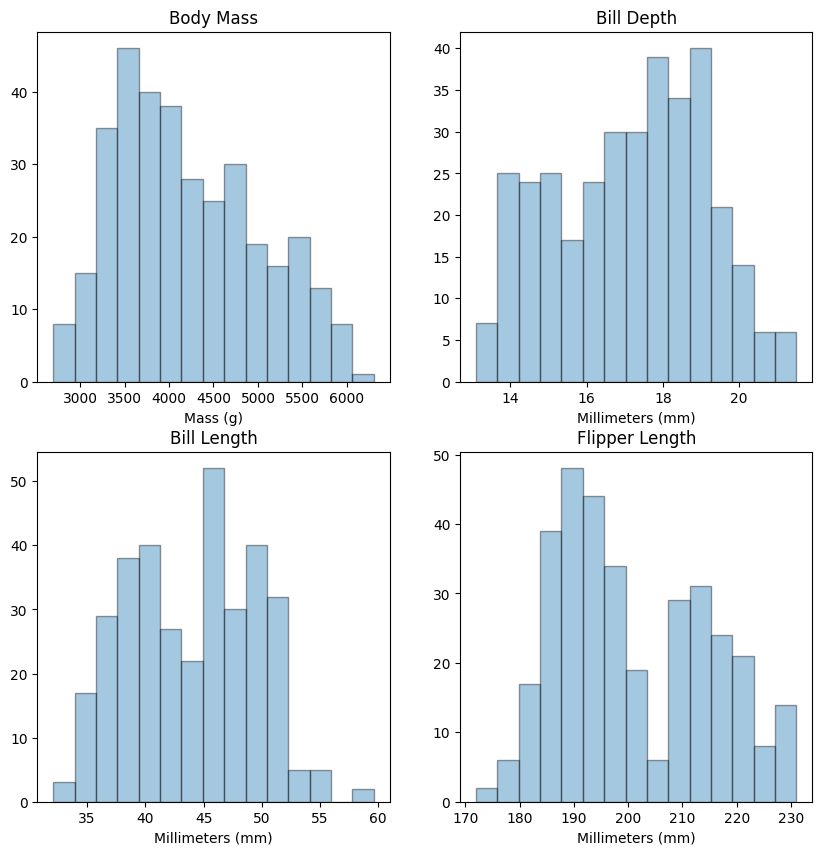

In [211]:

import matplotlib.pyplot as plt
fig, axes = plt.subplots(nrows=2,ncols=2,figsize=(10,10))

axes[0,0].hist(df['body_mass_g'], bins=15, edgecolor="black", alpha=0.4)
axes[0,0].set_title("Body Mass")
axes[0,0].set_xlabel('Mass (g)')

axes[1,0].hist(df['bill_length_mm'], bins=15, edgecolor="black", alpha=0.4)
axes[1,0].set_title("Bill Length")
axes[1,0].set_xlabel("Millimeters (mm)")

axes[0,1].hist(df['bill_depth_mm'], bins=15, edgecolor="black", alpha=0.4)
axes[0,1].set_title("Bill Depth")
axes[0,1].set_xlabel("Millimeters (mm)")

axes[1,1].hist(df['flipper_length_mm'], bins=15, edgecolor="black", alpha=0.4)
axes[1,1].set_title("Flipper Length")
axes[1,1].set_xlabel("Millimeters (mm)")

Next, I investigate the relationship between body mass and the other 3 numerical values.

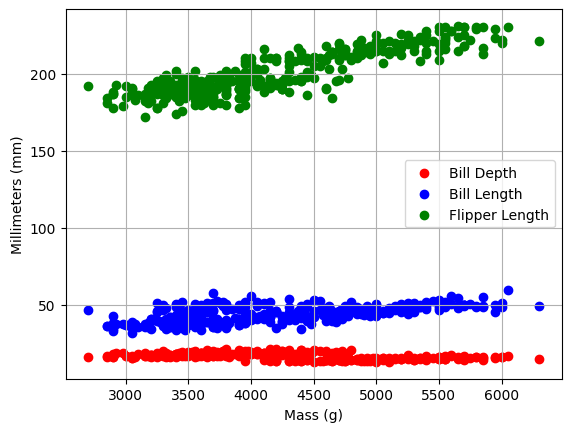

In [212]:
plt.clf()
plt.scatter(df['body_mass_g'],df['bill_depth_mm'], label="Bill Depth", color="red")
plt.scatter(df['body_mass_g'],df['bill_length_mm'], label="Bill Length", color="blue")
plt.scatter(df['body_mass_g'],df['flipper_length_mm'], label="Flipper Length", color="green")
plt.xlabel("Mass (g)")
plt.ylabel("Millimeters (mm)")
plt.legend()
plt.grid()
plt.show()

This graph reveals that mass has no significant correlation with bill depth, a very slight positive correlation with bill length, and significant positive correlation with flipper length. In other words, heavier penguins will have slightly longer bills and significantly longer flippers.

Also, there are seemingly two outliers: one with mass smaller than the rest of the dataset, and one with mass larger than the rest of the dataset. They still follow the overall trends of the dataset, so they are not necessary to remove.

Now, I investigate the relationship between sex and the 4 numerical values using bar graphs. The height of each bar is the mean of each value.

/tmp/ipykernel_1711/975649411.py:28: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


<Figure size 640x480 with 0 Axes>

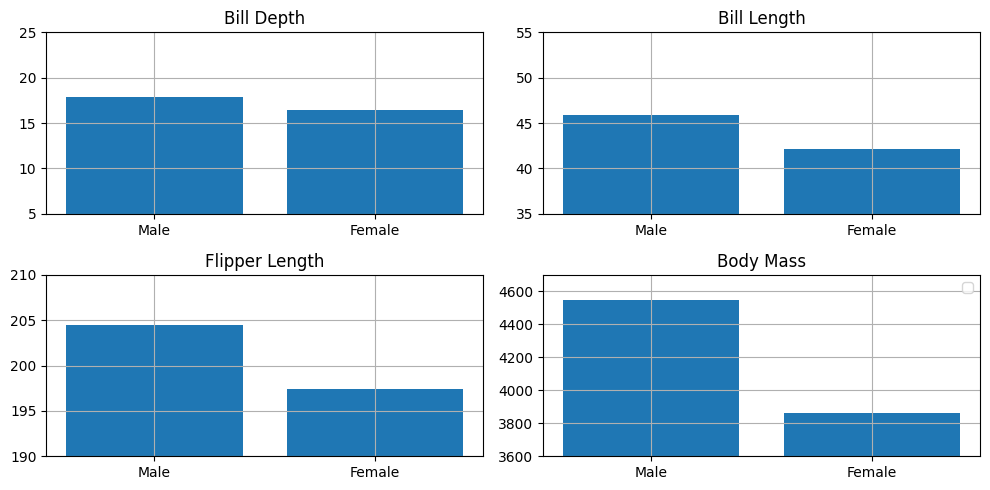

In [238]:
plt.clf()
male_set = df[df['sex']=='MALE']
female_set = df[df['sex']=='FEMALE']
fig, axes = plt.subplots(nrows=2,ncols=2,figsize=(10,5))

axes[0,0].grid(True)
axes[0,1].grid(True)
axes[1,0].grid(True)
axes[1,1].grid(True)

axes[0,0].bar(['Male', 'Female'], [male_set['bill_depth_mm'].mean(), female_set['bill_depth_mm'].mean()])
axes[0,0].set_title("Bill Depth")
axes[0,0].set_ylim(5,25)

axes[0,1].bar(['Male', 'Female'], [male_set['bill_length_mm'].mean(), female_set['bill_length_mm'].mean()])
axes[0,1].set_title("Bill Length")
axes[0,1].set_ylim(35,55)

axes[1,0].bar(['Male', 'Female'], [male_set['flipper_length_mm'].mean(), female_set['flipper_length_mm'].mean()])
axes[1,0].set_title("Flipper Length")
axes[1,0].set_ylim(190,210)

axes[1,1].bar(['Male', 'Female'], [male_set['body_mass_g'].mean(), female_set['body_mass_g'].mean()])
axes[1,1].set_title("Body Mass")
axes[1,1].set_ylim(3600,4700)

plt.tight_layout()
plt.show()


For visual clarity, the scale of the bill length, bill depth, and flipper length graphs are the same. The scale of the body mass is significantly larger.

We can see that males have larger bill and flipper lengths than females on average. This confirms my earlier hypothesis that sex is responsible for the two distinct peaks on the histograms of bill and flipper lengths.

Additionally, male penguins weigh much more than females on average.

Now, we investigate how these trends relate to species.

<Figure size 640x480 with 0 Axes>

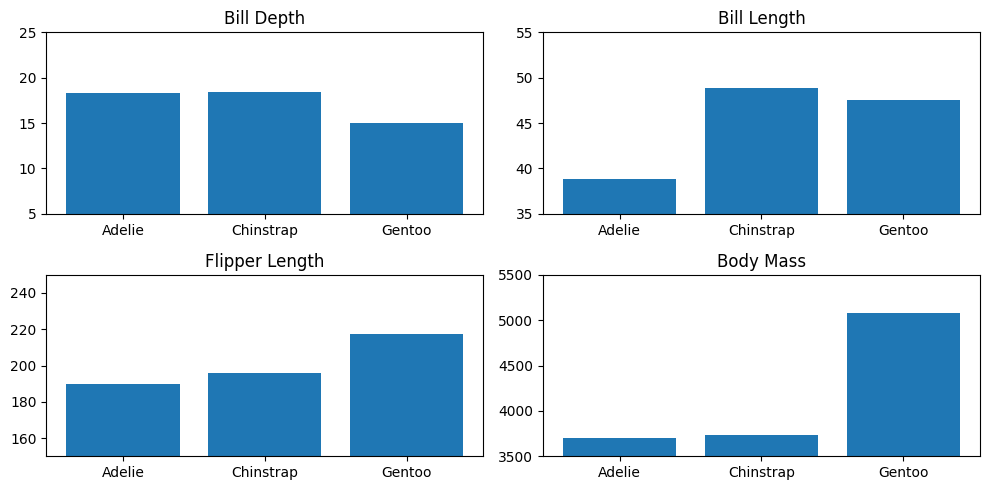

In [240]:
plt.clf()
adelie_set = df[df['species']=='Adelie']
chinstrap_set = df[df['species']=='Chinstrap']
gentoo_set = df[df['species']=='Gentoo']
fig, axes = plt.subplots(nrows=2,ncols=2,figsize=(10,5))

axes[0,0].bar(['Adelie', 'Chinstrap', 'Gentoo'], [adelie_set['bill_depth_mm'].mean(), chinstrap_set['bill_depth_mm'].mean(), gentoo_set['bill_depth_mm'].mean()])
axes[0,0].set_title("Bill Depth")
axes[0,0].set_ylim(5,25)

axes[0,1].bar(['Adelie', 'Chinstrap', 'Gentoo'], [adelie_set['bill_length_mm'].mean(), chinstrap_set['bill_length_mm'].mean(), gentoo_set['bill_length_mm'].mean()])
axes[0,1].set_title("Bill Length")
axes[0,1].set_ylim(35,55)

axes[1,0].bar(['Adelie', 'Chinstrap', 'Gentoo'], [adelie_set['flipper_length_mm'].mean(), chinstrap_set['flipper_length_mm'].mean(), gentoo_set['flipper_length_mm'].mean()])
axes[1,0].set_title("Flipper Length")
axes[1,0].set_ylim(150,250)

axes[1,1].bar(['Adelie', 'Chinstrap', 'Gentoo'], [adelie_set['body_mass_g'].mean(), chinstrap_set['body_mass_g'].mean(), gentoo_set['body_mass_g'].mean()])
axes[1,1].set_title("Body Mass")
axes[1,1].set_ylim(3500,5500)

plt.tight_layout()
plt.show()


Putting the previous two plots together, we plot species and sex simultaneously. This helps us see the sexual dimorphism of each species.

<Figure size 640x480 with 0 Axes>

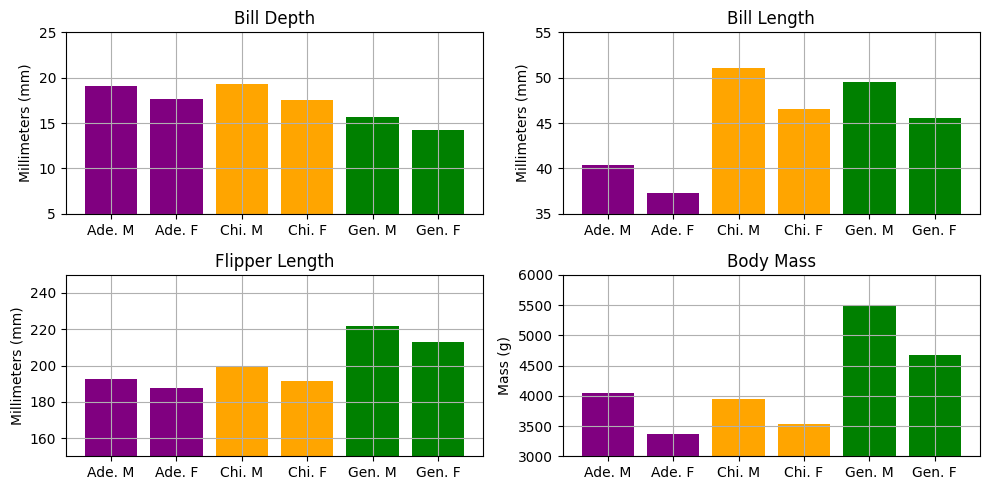

In [242]:
plt.clf()

# Dividing data by species and sex; creating list of sub-dataframes
adelie_m_set = df[(df['species']=='Adelie') & (df['sex']=='MALE')]
adelie_f_set = df[(df['species']=='Adelie') & (df['sex']=='FEMALE')]
chinstrap_m_set = df[(df['species']=='Chinstrap') & (df['sex']=='MALE')]
chinstrap_f_set = df[(df['species']=='Chinstrap') & (df['sex']=='FEMALE')]
gentoo_m_set = df[(df['species']=='Gentoo') & (df['sex']=='MALE')]
gentoo_f_set = df[(df['species']=='Gentoo') & (df['sex']=='FEMALE')]
all_sets = [adelie_m_set, adelie_f_set, chinstrap_m_set, chinstrap_f_set, gentoo_m_set, gentoo_f_set]

# Troubleshooting the for loop
'''
print(df)
for d in all_sets:
  print(d['bill_depth_mm'].mean())
'''

# Starting to graph
fig, axes = plt.subplots(nrows=2,ncols=2,figsize=(10,5))
bar_colors = ['purple', 'purple', 'orange', 'orange', 'green', 'green']

axes[0,0].grid(True)
axes[0,1].grid(True)
axes[1,0].grid(True)
axes[1,1].grid(True)

axes[0,0].bar(['Ade. M', 'Ade. F', 'Chi. M', 'Chi. F', 'Gen. M', 'Gen. F'], [d['bill_depth_mm'].mean() for d in all_sets], color=bar_colors)
axes[0,0].set_title("Bill Depth")
axes[0,0].set_ylim(5,25)
axes[0,0].set_ylabel("Millimeters (mm)")

axes[0,1].bar(['Ade. M', 'Ade. F', 'Chi. M', 'Chi. F', 'Gen. M', 'Gen. F'], [d['bill_length_mm'].mean() for d in all_sets], color=bar_colors)
axes[0,1].set_title("Bill Length")
axes[0,1].set_ylim(35,55)
axes[0,1].set_ylabel("Millimeters (mm)")

axes[1,0].bar(['Ade. M', 'Ade. F', 'Chi. M', 'Chi. F', 'Gen. M', 'Gen. F'], [d['flipper_length_mm'].mean() for d in all_sets], color=bar_colors)
axes[1,0].set_title("Flipper Length")
axes[1,0].set_ylim(150,250)
axes[1,0].set_ylabel("Millimeters (mm)")

axes[1,1].bar(['Ade. M', 'Ade. F', 'Chi. M', 'Chi. F', 'Gen. M', 'Gen. F'], [d['body_mass_g'].mean() for d in all_sets], color=bar_colors)
axes[1,1].set_title("Body Mass")
axes[1,1].set_ylim(3000,6000)
axes[1,1].set_ylabel("Mass (g)")

plt.tight_layout()
plt.show()


Sexual dimorphism is especially noticeable for the body mass of Gentoo and Adelie penguins, the flipper length of Chinstrap and Gentoo penguins, and the bill length of Chinstrap and Gentoo penguins. Overall, Gentoo penguins have the highest sexual dimorphism.

Finally, we investigate the relationship between island and species.

<Figure size 640x480 with 0 Axes>

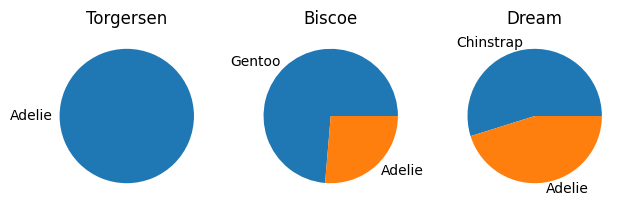

In [270]:
plt.clf()
fig, axes = plt.subplots(nrows=1,ncols=3)
torgersen_counts = df.loc[df['island']=='Torgersen', 'species'].value_counts()
biscoe_counts = df.loc[df['island']=='Biscoe', 'species'].value_counts()
dream_counts = df.loc[df['island']=='Dream', 'species'].value_counts()

axes[0].pie(torgersen_counts, labels=torgersen_counts.index)
axes[0].set_title("Torgersen")
axes[1].pie(biscoe_counts, labels=biscoe_counts.index)
axes[1].set_title("Biscoe")
axes[2].pie(dream_counts, labels=dream_counts.index)
axes[2].set_title("Dream")

plt.tight_layout()
plt.show()

As shown by the pie charts, Torgersen Island contains only Adelie penguins, while Biscoe contains a mix of Gentoo and Adelie, and Chinstrap contains a mix of Chinstrap and Adelie.

# **Key Take-aways: What did we learn from our analysis and visualizations?**
1. The original data set had a few flaws, mostly to do with missing values.
2. The three species had very different physical attributes: Gentoos were by far the heaviest species and also exhibited the greatest overall sexual dimorphism, with males having larger measurements than females. Meanwhile, chinstrap penguins, despite being the lightest on average, had the longest bills. Finally, Adelie penguins are overall quite petite, weighing similarly to Chinstraps and having dramatically shorter bills than the other two species.
3. We found that mass and flipper length are the most strongly positively correlated physical measurements.
4. Geographic demographics: Adelie penguins can be found on all three islands, while Gentoo penguins are found exclusively on Biscoe Island, and Chinstrap penguins are found exclusively on Dream Island.
